# Image Color Palette Generator

NOTE: as this main file currently exists, it is meant for developer testing of new functionality. 

It will be cleaned up and turned into a user-facing interface in later commits once functionality is fully implemented. Feel free to use this file as a place to do informal testing. This is also helpful so us group members can see how the code actually works & functions, especially with how it's called and referenced by other parts of the codebase.


In [1]:
from image_analyzer import ImageAnalyzer
from color_utils import rgb_to_hex
from IPython.display import display

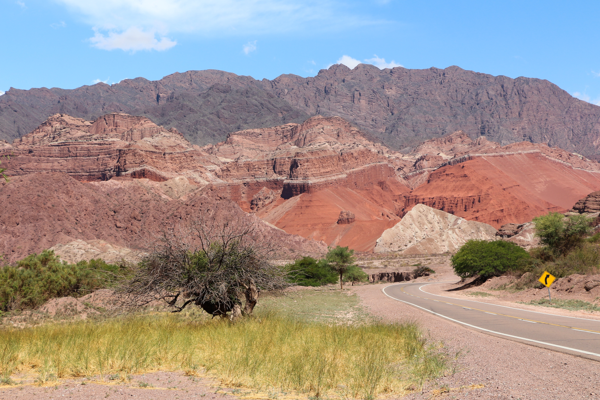

Image size: (4990, 3327)
Pixel array shape: (3327, 4990, 3)


In [7]:
analyzer = ImageAnalyzer("images/Quebrada_de_las_Conchas_04.jpg")

image = analyzer.load_image()
preview = image.copy()
preview.thumbnail((600, 400))
display(preview)

print("Image size:", analyzer.get_image_size())
print("Pixel array shape:", analyzer.get_pixels().shape)

In [3]:
unique_colors = analyzer.get_unique_colors()

print("Number of unique colors:", len(unique_colors))
for color in unique_colors[:10]:
    print(f"RGB: {color}, HEX: {rgb_to_hex(color)}")

Number of unique colors: 330321
RGB: (0, 0, 0), HEX: #000000
RGB: (0, 0, 2), HEX: #000002
RGB: (0, 0, 4), HEX: #000004
RGB: (0, 0, 5), HEX: #000005
RGB: (0, 0, 7), HEX: #000007
RGB: (0, 0, 9), HEX: #000009
RGB: (0, 0, 12), HEX: #00000C
RGB: (0, 1, 0), HEX: #000100
RGB: (0, 1, 2), HEX: #000102
RGB: (0, 1, 3), HEX: #000103


### Dominant Color Extraction

Extract dominant colors based on frequency and color diversity, and display their RGB values, HEX codes, and proportions in descending order.

In [4]:
image_paths = [
    "images/sample.png",
    "images/Emosson_Construction.jpg",
    "images/Quebrada_de_las_Conchas_04.jpg"
]

color_counts = [5, 8, 12]

# Test each image with different palette sizes
for path in image_paths:
    analyzer = ImageAnalyzer(path)
    analyzer.load_image()

    print(f"\nImage: {path}")

    for num_colors in color_counts:
        dominant_colors = analyzer.extract_dominant_colors(num_colors)

        print(f"\nRequested colors: {num_colors}")
        for color, proportion in dominant_colors.items():
            print(f"RGB: {color}, HEX: {rgb_to_hex(color)}, Proportion: {proportion:.2f}%")

        print(f"Total proportion: {sum(dominant_colors.values()):.2f}%")

    print("-" * 50)


Image: images/sample.png

Requested colors: 5
RGB: (255, 255, 255), HEX: #FFFFFF, Proportion: 44.77%
RGB: (142, 112, 182), HEX: #8E70B6, Proportion: 21.65%
RGB: (178, 171, 222), HEX: #B2ABDE, Proportion: 11.87%
RGB: (130, 174, 53), HEX: #82AE35, Proportion: 10.89%
RGB: (48, 103, 36), HEX: #306724, Proportion: 10.82%
Total proportion: 100.00%

Requested colors: 8
RGB: (255, 255, 255), HEX: #FFFFFF, Proportion: 22.34%
RGB: (224, 226, 247), HEX: #E0E2F7, Proportion: 11.59%
RGB: (178, 171, 222), HEX: #B2ABDE, Proportion: 11.38%
RGB: (234, 228, 194), HEX: #EAE4C2, Proportion: 11.33%
RGB: (162, 107, 126), HEX: #A26B7E, Proportion: 10.89%
RGB: (130, 174, 53), HEX: #82AE35, Proportion: 10.83%
RGB: (142, 112, 182), HEX: #8E70B6, Proportion: 10.82%
RGB: (48, 103, 36), HEX: #306724, Proportion: 10.82%
Total proportion: 100.00%

Requested colors: 12
RGB: (255, 255, 255), HEX: #FFFFFF, Proportion: 21.76%
RGB: (224, 226, 247), HEX: #E0E2F7, Proportion: 11.47%
RGB: (234, 228, 194), HEX: #EAE4C2, Pro

### Temporary Visualization for Algorithm Testing

Used to visually compare extraction results at different palette sizes. This was used during development/refinement of dominant color extraction.


Image: images/sample.png


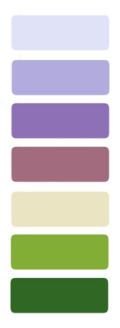

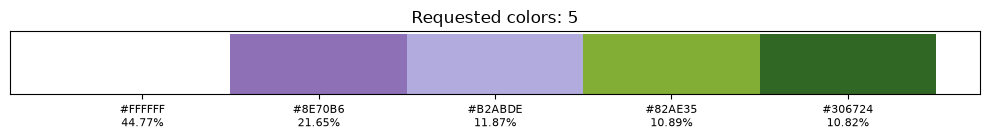

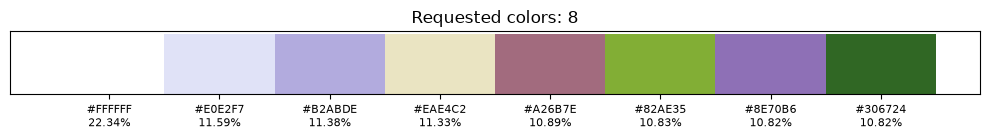

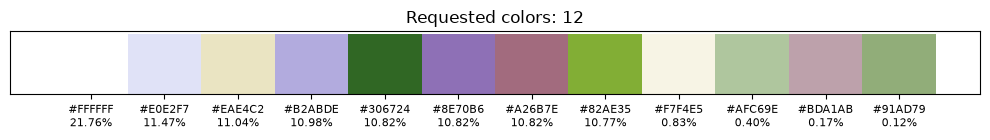


Image: images/Emosson_Construction.jpg


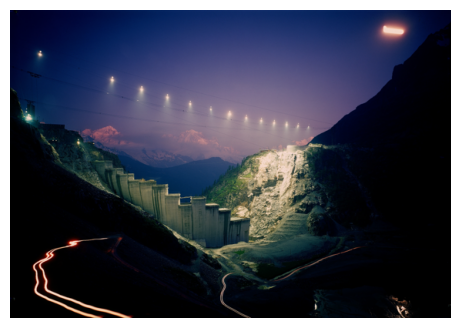

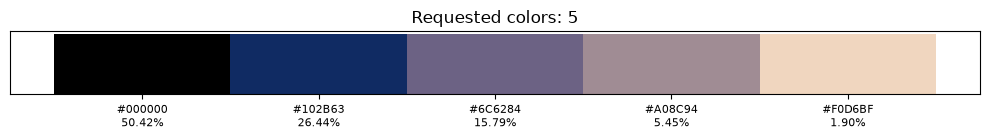

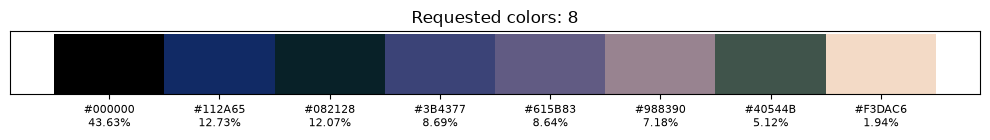

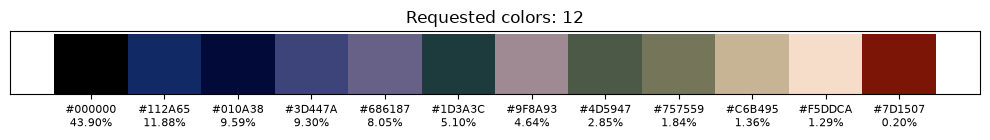


Image: images/Quebrada_de_las_Conchas_04.jpg


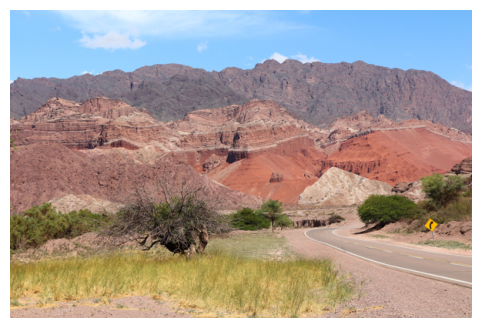

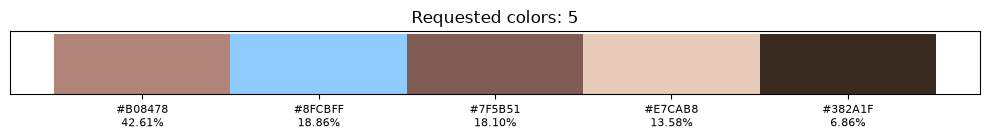

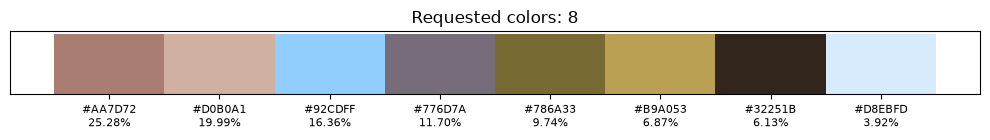

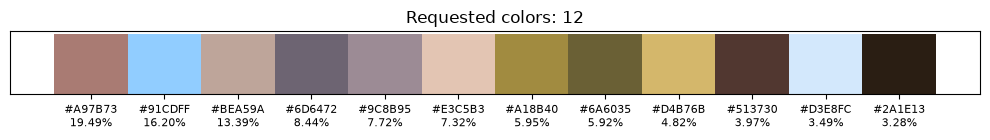

In [6]:
import matplotlib.pyplot as plt

for path in image_paths:
    analyzer = ImageAnalyzer(path)
    analyzer.load_image()

    print(f"\nImage: {path}")

    plt.figure(figsize=(8, 4))
    preview = analyzer.image.copy()
    preview.thumbnail((600, 400))
    plt.imshow(preview)
    plt.axis("off")
    plt.show()

    for num_colors in color_counts:
        dominant_colors = analyzer.extract_dominant_colors(num_colors)
        hex_colors = [rgb_to_hex(color) for color in dominant_colors]

        # Display the extracted colors next to each other
        plt.figure(figsize=(10, 1.5))
        plt.bar(
            range(len(hex_colors)),
            [1] * len(hex_colors),
            color=hex_colors,
            width=1
        )

        labels = [f"{rgb_to_hex(color)}\n{proportion:.2f}%"
                  for color, proportion in dominant_colors.items()]
        plt.xticks(range(len(labels)), labels, fontsize=8)
        plt.yticks([])
        plt.title(f"Requested colors: {num_colors}")
        plt.tight_layout()
        plt.show()